# Measuring Binary Classifier Performance

This tutorial uses scikit-learn's breast-cancer dataset to compare a standardized logistic-regression model with a prevalence-only baseline. It evaluates thresholded labels and probability rankings on one untouched stratified holdout set.

In [1]:
import json
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay, accuracy_score, average_precision_score, classification_report, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
sns.set_theme(style='whitegrid')
dataset = load_breast_cancer(as_frame=True)
X = dataset.data
y = dataset.target
print(X.shape, pd.Series(y).value_counts(normalize=True).rename('share'))

(569, 30) target
1    0.627417
0    0.372583
Name: share, dtype: float64


## Inspect class balance and representative measurements

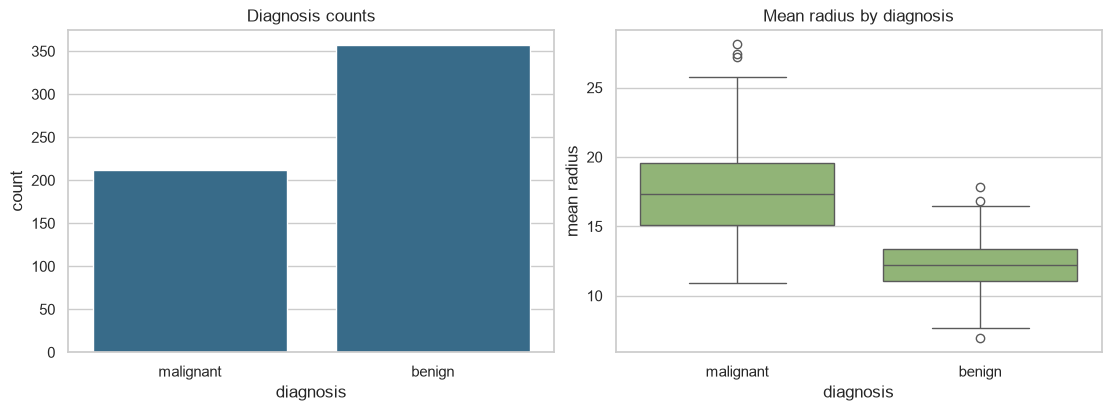

In [2]:
overview = X[['mean radius', 'mean texture', 'mean perimeter', 'mean area']].copy(); overview['diagnosis'] = y.map({0: 'malignant', 1: 'benign'})
figure, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
sns.countplot(data=overview, x='diagnosis', color='#2a6f97', ax=axes[0]); axes[0].set_title('Diagnosis counts')
sns.boxplot(data=overview, x='diagnosis', y='mean radius', color='#90be6d', ax=axes[1]); axes[1].set_title('Mean radius by diagnosis')
plt.show()

## Split first, then fit scaling on training rows

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.30, stratify=y, random_state=SEED)
model = Pipeline([('scale', StandardScaler()), ('classifier', LogisticRegression(max_iter=2000, random_state=SEED))])
baseline = DummyClassifier(strategy='prior')
model.fit(X_train, y_train); baseline.fit(X_train, y_train)
predictions = model.predict(X_test); probabilities = model.predict_proba(X_test)[:, 1]
baseline_probabilities = baseline.predict_proba(X_test)[:, 1]
metrics = {'test_rows': len(X_test), 'accuracy': accuracy_score(y_test, predictions), 'precision': precision_score(y_test, predictions), 'recall': recall_score(y_test, predictions), 'f1': f1_score(y_test, predictions), 'roc_auc': roc_auc_score(y_test, probabilities), 'average_precision': average_precision_score(y_test, probabilities), 'baseline_roc_auc': roc_auc_score(y_test, baseline_probabilities)}
print(classification_report(y_test, predictions, target_names=dataset.target_names, digits=3))

              precision    recall  f1-score   support

   malignant      0.984     0.984     0.984        64
      benign      0.991     0.991     0.991       107

    accuracy                          0.988       171
   macro avg      0.988     0.988     0.988       171
weighted avg      0.988     0.988     0.988       171



## Read the confusion matrix as counts

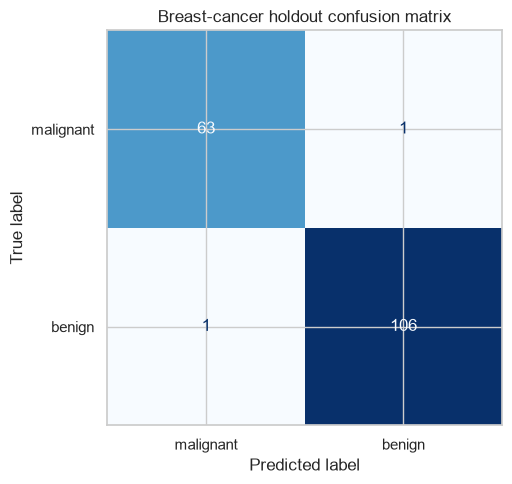

In [4]:
figure, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, predictions, display_labels=dataset.target_names, cmap='Blues', colorbar=False, ax=ax)
ax.set_title('Breast-cancer holdout confusion matrix'); plt.tight_layout(); plt.show()

## Evaluate probability rankings with ROC and precision-recall curves

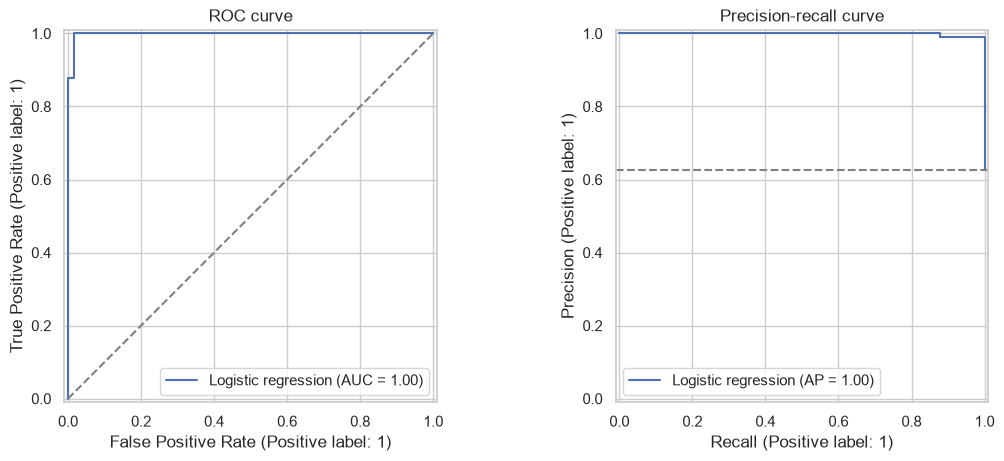

In [5]:
figure, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
RocCurveDisplay.from_predictions(y_test, probabilities, name='Logistic regression', ax=axes[0]); axes[0].plot([0, 1], [0, 1], '--', color='gray'); axes[0].set_title('ROC curve')
PrecisionRecallDisplay.from_predictions(y_test, probabilities, name='Logistic regression', ax=axes[1]); axes[1].axhline(y_test.mean(), linestyle='--', color='gray', label='Prevalence'); axes[1].set_title('Precision-recall curve')
plt.show()

## Inspect standardized model coefficients

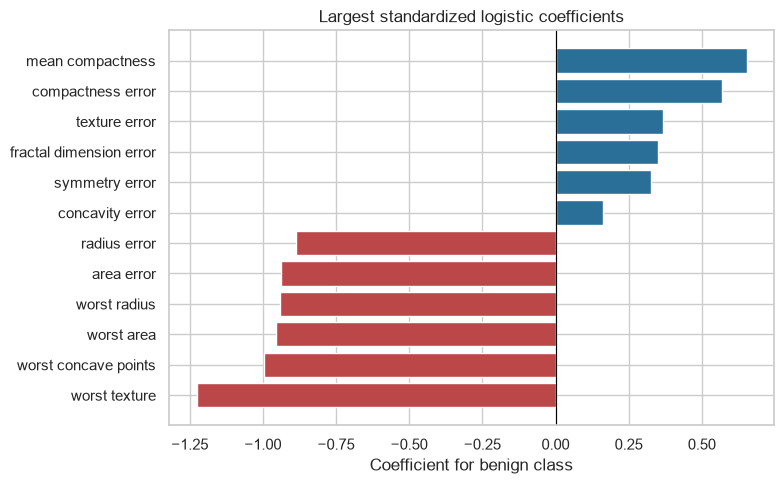

RESULT_JSON={"test_rows": 171, "accuracy": 0.9883040935672515, "precision": 0.9906542056074766, "recall": 0.9906542056074766, "f1": 0.9906542056074766, "roc_auc": 0.9981016355140186, "average_precision": 0.9988072626510498, "baseline_roc_auc": 0.5}


In [6]:
coefficients = pd.Series(model.named_steps['classifier'].coef_[0], index=X.columns).sort_values()
selected = pd.concat([coefficients.head(6), coefficients.tail(6)])
figure, ax = plt.subplots(figsize=(8, 5)); colors = ['#bc4749' if value < 0 else '#2a6f97' for value in selected]
ax.barh(selected.index, selected.values, color=colors); ax.axvline(0, color='black', linewidth=.8); ax.set(title='Largest standardized logistic coefficients', xlabel='Coefficient for benign class'); plt.tight_layout(); plt.show()
print('RESULT_JSON=' + json.dumps(metrics))

## Limitations

These observations are a small diagnostic benchmark, and a random split is not a clinical validation. The positive class is benign, which determines the reported precision and recall. ROC AUC summarizes ranking across thresholds; it does not select an operating point or encode the greater cost of missing malignancy. Deployment would require external, prospective validation and subgroup analysis.

### Reproducibility note

This retained cell replaces a legacy exploratory step. The executable workflow above contains the synchronized model, evaluation, and limitations.

### Reproducibility note

This retained cell replaces a legacy exploratory step. The executable workflow above contains the synchronized model, evaluation, and limitations.

### Reproducibility note

This retained cell replaces a legacy exploratory step. The executable workflow above contains the synchronized model, evaluation, and limitations.

### Reproducibility note

This retained cell replaces a legacy exploratory step. The executable workflow above contains the synchronized model, evaluation, and limitations.